In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import time
import jax.numpy as jnp
import equinox as eqx
import optax
import matplotlib.pyplot as plt

from pathlib import Path
from jax import random, vmap
from jax.lax import scan
from jax.tree_util import tree_map, tree_flatten
from jax.nn import gelu

%config InlineBackend.figure_format='retina'

# DeepONet

The goal is the same as in the FNO notebook: to learn the solution operator $\mathcal{G}: v \longrightarrow u$ from a dataset of pairs $(v_i, u_i)$. The DeepONet takes a different route and is built on the following observation. The solution $u=\mathcal{G}(v)$ is a function of $x$, and we can approximate it by a linear combination of $p$ basis functions,
$$
u(x) \approx \sum_{k=1}^{p} c_k(v)\,\phi_k(x).
$$
The basis functions $\phi_k$ are the same for all inputs, and the coefficients $c_k$ depend on the input function $v$. DeepONet uses two networks to represent them:

- the **trunk network** takes the coordinate $x$ and returns the vector $\phi(x)=(\phi_1(x),\dots,\phi_p(x))$. It *learns the basis* in which the solutions are represented;
- the **branch network** takes the input function $v$ and returns the vector of coefficients $c(v)=(c_1(v),\dots,c_p(v))$.

The output is the scalar product $u_\theta(v)(x)=c(v)\cdot\phi(x)$. The trunk network is evaluated at any point $x$, so, unlike for the FNO, the output does not have to be on a grid. The branch network, however, needs a finite-dimensional input, so the function $v$ has to be reduced to a vector first. The original paper evaluates $v$ at a fixed set of *sensors*. Here $v$ is projected on `n_obs` piecewise linear hat functions $\psi_j$ on a uniform grid: the vector $g$ of the coefficients solves
$$
G g = \big(\langle v,\psi_j\rangle\big)_{j}, \qquad G_{ij}=\langle\psi_i,\psi_j\rangle,
$$
which is the $L^2$ projection (the same Galerkin step as in the FEM notebook). If $v$ has several channels (e.g., $a(x)$ and $f(x)$), the projections of all channels are concatenated. The number of the branch inputs is therefore independent of the number of grid points.

### Implementation in this notebook

- the **branch network** is a multilayer perceptron with GELU activations;
- the **trunk network** is a multilayer perceptron with $\sin$ activations, as for the Siren in the PINN tutorials: the first layer is multiplied by $10$, which lets the learned basis contain high frequencies, which are needed to represent kinks and shocks;
- the weights are initialised with small normal values (scale `s`);
- the loss is the squared $\ell_2$ distance between the predicted and the true solution (summed over the grid), averaged over a minibatch;
- we train with the AdamW optimiser with a small weight decay and a cosine decay of the learning rate. The hyperparameters were tuned a little (see the summary at the end).

The architecture is *linear in the trunk output*, so DeepONet is very close to the classical reduced-basis methods, with the difference that both the basis and the map from $v$ to the coefficients are learned. Compared to the FNO it has no built-in inductive bias for translation-invariant operators, so one should not expect the same accuracy for the problems where the spectral convolution is natural.

*References:* L. Lu, P. Jin, G. Pang, Z. Zhang, G. E. Karniadakis, [Learning nonlinear operators via DeepONet based on the universal approximation theorem of operators](https://arxiv.org/abs/1910.03193), Nature Machine Intelligence 3, 2021; for the optimiser: I. Loshchilov, F. Hutter, [Decoupled Weight Decay Regularization](https://arxiv.org/abs/1711.05101), ICLR 2019.

In [2]:
class DeepONet(eqx.Module):
    trunk_W: list
    trunk_b: list
    branch_W: list
    branch_b: list
    s0: float = eqx.field(static=True)

    def __init__(self, N_layers, N_f_branch, D, key, s=1.0, s0=10.0):
        self.s0 = s0
        n_obs, n_basis, n_channels = N_f_branch
        N_branch, N_trunk = N_layers

        keys = random.split(key)
        keys_branch = random.split(keys[0], N_branch)
        keys_trunk = random.split(keys[1], N_trunk)
        n_branch = [n_obs * n_channels, ] + [n_basis, ]*N_branch
        n_trunk = [D, ] + [n_basis, ]*N_trunk

        self.trunk_W = [s*random.normal(key, (n_out, n_in)) for key, n_out, n_in in zip(keys_trunk, n_trunk[1:], n_trunk[:-1])]
        self.branch_W = [s*random.normal(key, (n_out, n_in)) for key, n_out, n_in in zip(keys_branch, n_branch[1:], n_branch[:-1])]
        self.trunk_b = [jnp.zeros([n_basis,] + [1,]*D) for _ in range(N_trunk)]
        self.branch_b = [jnp.zeros((n_basis,)) for _ in range(N_branch)]

    def __call__(self, feature, x, basis, inv_G):
        c = self.branch_net(feature, basis, inv_G)  # coefficients, shape (n_basis,)
        phi = self.trunk_net(x)  # learned basis at the points x, shape (n_basis, N_x)
        return jnp.expand_dims(c @ phi, 0)

    def branch_net(self, feature, basis, inv_G):
        # project every channel on the hat functions and concatenate the results
        u = vmap(project, in_axes=(0, None, None))(feature, basis, inv_G).reshape(-1,)
        for W, b in zip(self.branch_W, self.branch_b):
            u = gelu(W @ u + b)
        return u

    def trunk_net(self, x):
        s = self.s0  # frequency scale of the first layer
        for W, b in zip(self.trunk_W, self.trunk_b):
            x = jnp.sin(s * (W @ x + b))
            s = 1
        return x

def get_observation_data(N_basis, x):
    # N_basis hat functions on a uniform grid of [0, 1], evaluated at the points x, and the inverse of their Gram matrix
    x_ = jnp.linspace(0, 1, N_basis+2)
    I = jnp.eye(N_basis)
    b = jnp.array([jnp.interp(x, x_, jnp.pad(e, (1, 1))) for e in I])
    inv_G = jnp.linalg.inv(b @ b.T)
    return b, inv_G

def project(f, b, inv_G):
    # coefficients of the L2 projection of f on the hat functions
    return inv_G @ (f @ b.T)

### Loss and optimisation step

The loss for a single sample is $\|u_\theta(v)-u\|_2^2$, and for a minibatch it is the average over its samples. As in the PINN tutorials, the training loop is compiled with `scan`, and the indices of the minibatches are pregenerated in advance.

In [3]:
def l2_loss(model, input, target, x, b, inv_G):
    X = model(input, x, b, inv_G)
    error = jnp.mean(jnp.sum(((X - target).reshape(target.shape[0], -1,))**2, axis=1))
    return error

def batch_l2_loss(model, input, target, x, b, inv_G):
    res = vmap(l2_loss, in_axes=(None, 0, 0, None, None, None))(model, input, target, x, b, inv_G)
    return jnp.mean(res)

l2_compute_loss_and_grads = eqx.filter_value_and_grad(batch_l2_loss)

def l2_make_step_scan(carry, n, optim):
    model, features, targets, x, b, inv_G, opt_state = carry
    loss, grads = l2_compute_loss_and_grads(model, features[n], targets[n], x, b, inv_G)
    updates, opt_state = optim.update(grads, opt_state, eqx.filter(model, eqx.is_array))
    model = eqx.apply_updates(model, updates)
    return [model, features, targets, x, b, inv_G, opt_state], loss

def make_prediction_scan(carry, i):
    model, features, coords, b, inv_G = carry
    prediction = model(features[i], coords, b, inv_G)
    return carry, prediction

# Datasets

We use the datasets generated in the previous tutorials, 1000 samples each on a grid of 512 points, of which we keep every 4th point (128 points): the datasets are redundant, and the linear interpolation from the coarse grid reproduces the solutions with the error of about 2% for Burgers and below 0.5% for the diffusion problems, which is less than the error of the networks. The errors below are computed on the coarse grid. The first 900 samples are used for training, and the last 100 are the test set, which is never seen by the network during the training.

| name | input $v$ | output $u$ |
|---|---|---|
| Burgers | initial condition $u_0(x)$ | solution of the Burgers equation at the final time |
| Diffusion | coefficient $a(x)$ and right-hand side $f(x)$ (two channels) | solution of $-\frac{d}{dx}\left(a(x) \frac{du(x)}{dx}\right)=f(x)$ |
| Diffusion, constant source | coefficient $a(x)$ (one channel) | solution of $-\frac{d}{dx}\left(a(x) \frac{du(x)}{dx}\right)=f(x)$ with a constant $f(x)$ |

The inputs and the outputs are divided by their maximal absolute values. The grid coordinates are passed to the network as an additional input channel.

In [4]:
# the repository root is the closest parent of the working directory that contains `notebooks`
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks").is_dir())
data_dir = root / "data"

In [5]:
def load_dataset(dataset_name, stride=4):
    # returns arrays of shape (samples, channels, grid points), coordinates of shape (1, grid points)
    if dataset_name == 'Burgers':
        data = jnp.load(data_dir / "burgers_dataset.npz")
        features = jnp.expand_dims(data["initial condition"], 1)
    elif dataset_name == 'Diffusion':
        data = jnp.load(data_dir / "diffusion_dataset.npz")
        features = jnp.stack([data["diffusion coefficient"], data["righ-hand side"]], axis=1)
    elif dataset_name == 'Diffusion_constant_source':
        data = jnp.load(data_dir / "diffusion_dataset_2.npz")
        features = jnp.expand_dims(data["diffusion coefficient"], axis=1)
    targets = jnp.expand_dims(data["solution"], 1)
    coordinates = jnp.expand_dims(data["grid points"], 0)

    # keep every stride-th grid point
    features, targets, coordinates = features[:, :, ::stride], targets[:, :, ::stride], coordinates[:, ::stride]

    features = features / jnp.max(jnp.abs(features))
    targets = targets / jnp.max(jnp.abs(targets))
    return features, targets, coordinates

# Training

All three problems are trained with the same network and the same hyperparameters, which were chosen by a small tuning (see the summary at the end). The function `train` loads a dataset, trains the DeepONet, and returns the model together with the training history and the relative errors $\|u_\theta-u\|_2/\|u\|_2$ of all samples. For the training and the test sets we report the mean, the median, the minimal and the maximal error. The median is less sensitive than the mean to a few samples with a large error, and the minimum and the maximum show the range of the quality.

In [6]:
N_layers = [6, 6]  # depth of the branch and the trunk networks
n_obs = 30  # number of hat functions used to project the input
n_basis = 200  # number of learned basis functions
N_epoch = 1000
N_train = 900
N_batch = 11
learning_rate = 1e-3  # initial value, decays to 1e-3 of it by the end of the training (cosine schedule)
weight_decay = 1e-2
N_run = N_epoch * N_train // N_batch  # total number of updates

In [7]:
def train(dataset_name, key=random.PRNGKey(45)):
    features, targets, coordinates = load_dataset(dataset_name)
    D = features.ndim - 2  # dimension of the domain
    keys = random.split(key)

    N_f_branch = [n_obs, n_basis, features.shape[1]]
    model = DeepONet(N_layers, N_f_branch, D, keys[0], s=1e-2)
    b, inv_G = get_observation_data(n_obs, coordinates[0])
    model_size = sum(tree_map(lambda x: jnp.size(x), tree_flatten(model)[0], is_leaf=eqx.is_array))
    schedule = optax.cosine_decay_schedule(learning_rate, N_run, alpha=1e-3)
    optim = optax.adamw(learning_rate=schedule, weight_decay=weight_decay)
    opt_state = optim.init(eqx.filter(model, eqx.is_array))
    n = random.choice(keys[1], N_train, shape=(N_run, N_batch))
    carry = [model, features, targets, coordinates, b, inv_G, opt_state]

    make_step_scan_ = lambda carry, n: l2_make_step_scan(carry, n, optim)

    start = time.time()
    carry, history = scan(make_step_scan_, carry, n)
    history.block_until_ready()
    training_time = time.time() - start
    model = carry[0]

    # relative errors of all samples
    ind = jnp.arange(features.shape[0])
    predictions = scan(make_prediction_scan, [model, features, coordinates, b, inv_G], ind)[1]
    errors = (jnp.linalg.norm(predictions - targets, axis=2) / jnp.linalg.norm(targets, axis=2))[:, 0]

    print(f"Number of parameters: {model_size}")
    print(f"Training time: {training_time:.1f} s")
    print("Relative error      mean    median       min       max")
    for name, e in [("train", errors[:N_train]), ("test", errors[N_train:])]:
        print(f"  {name:<12} {jnp.mean(e):9.4f} {jnp.median(e):9.4f} {jnp.min(e):9.4f} {jnp.max(e):9.4f}")
    return model, history, errors, predictions, targets, coordinates

# Visualisation

For every dataset we plot

- the **training curve**: the loss on the minibatches (light grey) and its average over an epoch (black);
- the **best and the worst samples of the test set**, ranked by the relative error: the prediction against the reference solution and the pointwise error $|u_\theta-u|/\max|u|$. The values are those of the normalised data.

The best and the worst samples correspond to the minimal and the maximal errors reported above. They show the range of the quality of the network, and the mean error alone does not: a small mean error may hide a few samples with a large error.

In [8]:
def plot_results(history, errors, predictions, targets, coordinates, figure_name=None):
    if figure_name is not None and not data_dir.exists():
        data_dir.mkdir()

    # training curve
    epochs = jnp.arange(1, N_epoch + 1)
    steps_per_epoch = N_run // N_epoch  # N_batch does not divide N_train, so an epoch is only approximately this many updates
    fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
    ax.plot(jnp.arange(N_run) / (N_train / N_batch), history, color="lightgray", linewidth=0.5, label="minibatch")
    ax.plot(epochs, history[:N_epoch * steps_per_epoch].reshape(N_epoch, steps_per_epoch).mean(axis=1), color="black", label="epoch average")
    ax.set_yscale("log")
    ax.set_xlabel("epoch", fontsize="x-large")
    ax.set_ylabel("loss", fontsize="x-large")
    ax.legend()
    plt.tight_layout()

    if figure_name is not None:
        plt.savefig(data_dir / f"{figure_name}_convergence.pdf", format='pdf', bbox_inches='tight')

    # best and worst samples of the test set
    test_errors = errors[N_train:]
    selected = {"best": N_train + jnp.argmin(test_errors), "worst": N_train + jnp.argmax(test_errors)}
    x = coordinates[0]
    fig, axes = plt.subplots(2, 2, figsize=(10, 7))
    for row, (name, i) in zip(axes, selected.items()):
        u, u_pred = targets[i, 0], predictions[i, 0]
        row[0].plot(x, u, color="black", label="reference", linewidth=1.0)
        row[0].plot(x, u_pred, color="tab:red", dashes=[4, 4, 4, 4], label="DeepONet", linewidth=2.5)
        row[0].set_ylabel("$u(x)$", fontsize="x-large")
        row[0].set_title(f"{name} test sample (#{int(i)}), relative error {errors[i]:.3f}")
        row[0].legend()
        row[1].plot(x, jnp.abs(u_pred - u) / jnp.max(jnp.abs(u)), color="black")
        row[1].set_yscale("log")
        row[1].set_ylabel("$|u_\\theta - u| / \\max|u|$", fontsize="x-large")
        for ax in row:
            ax.set_xlabel("$x$", fontsize="x-large")
    plt.tight_layout()

    if figure_name is not None:
        plt.savefig(data_dir / f"{figure_name}_solutions.pdf", format='pdf', bbox_inches='tight')

## Burgers equation

Number of parameters: 408600
Training time: 45.5 s
Relative error      mean    median       min       max


  train           0.1123    0.1096    0.0185    0.2430


  test            0.2772    0.2689    0.1051    0.4926


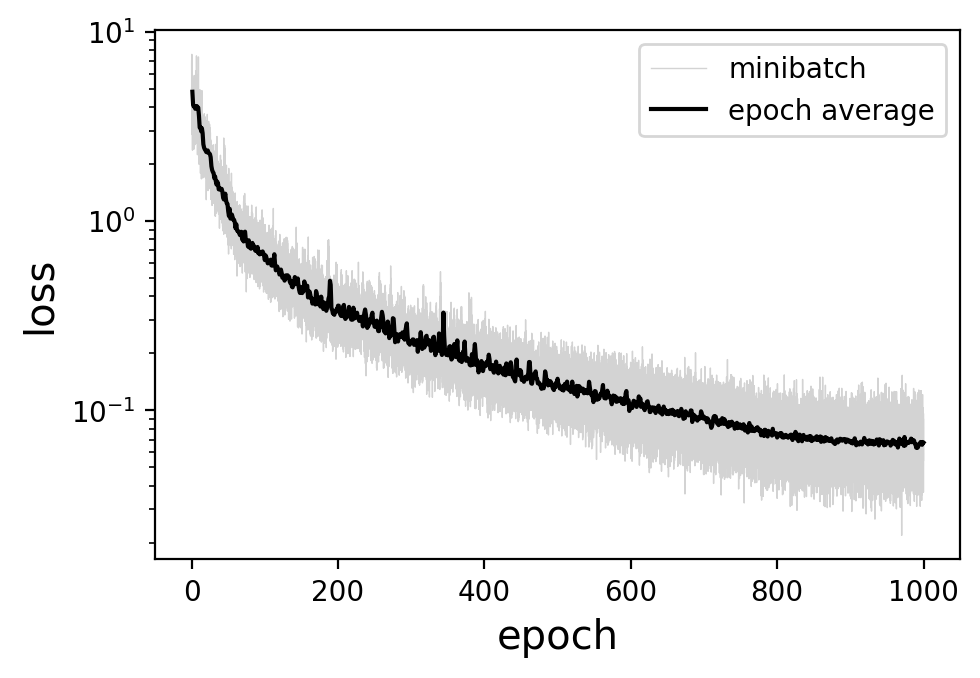

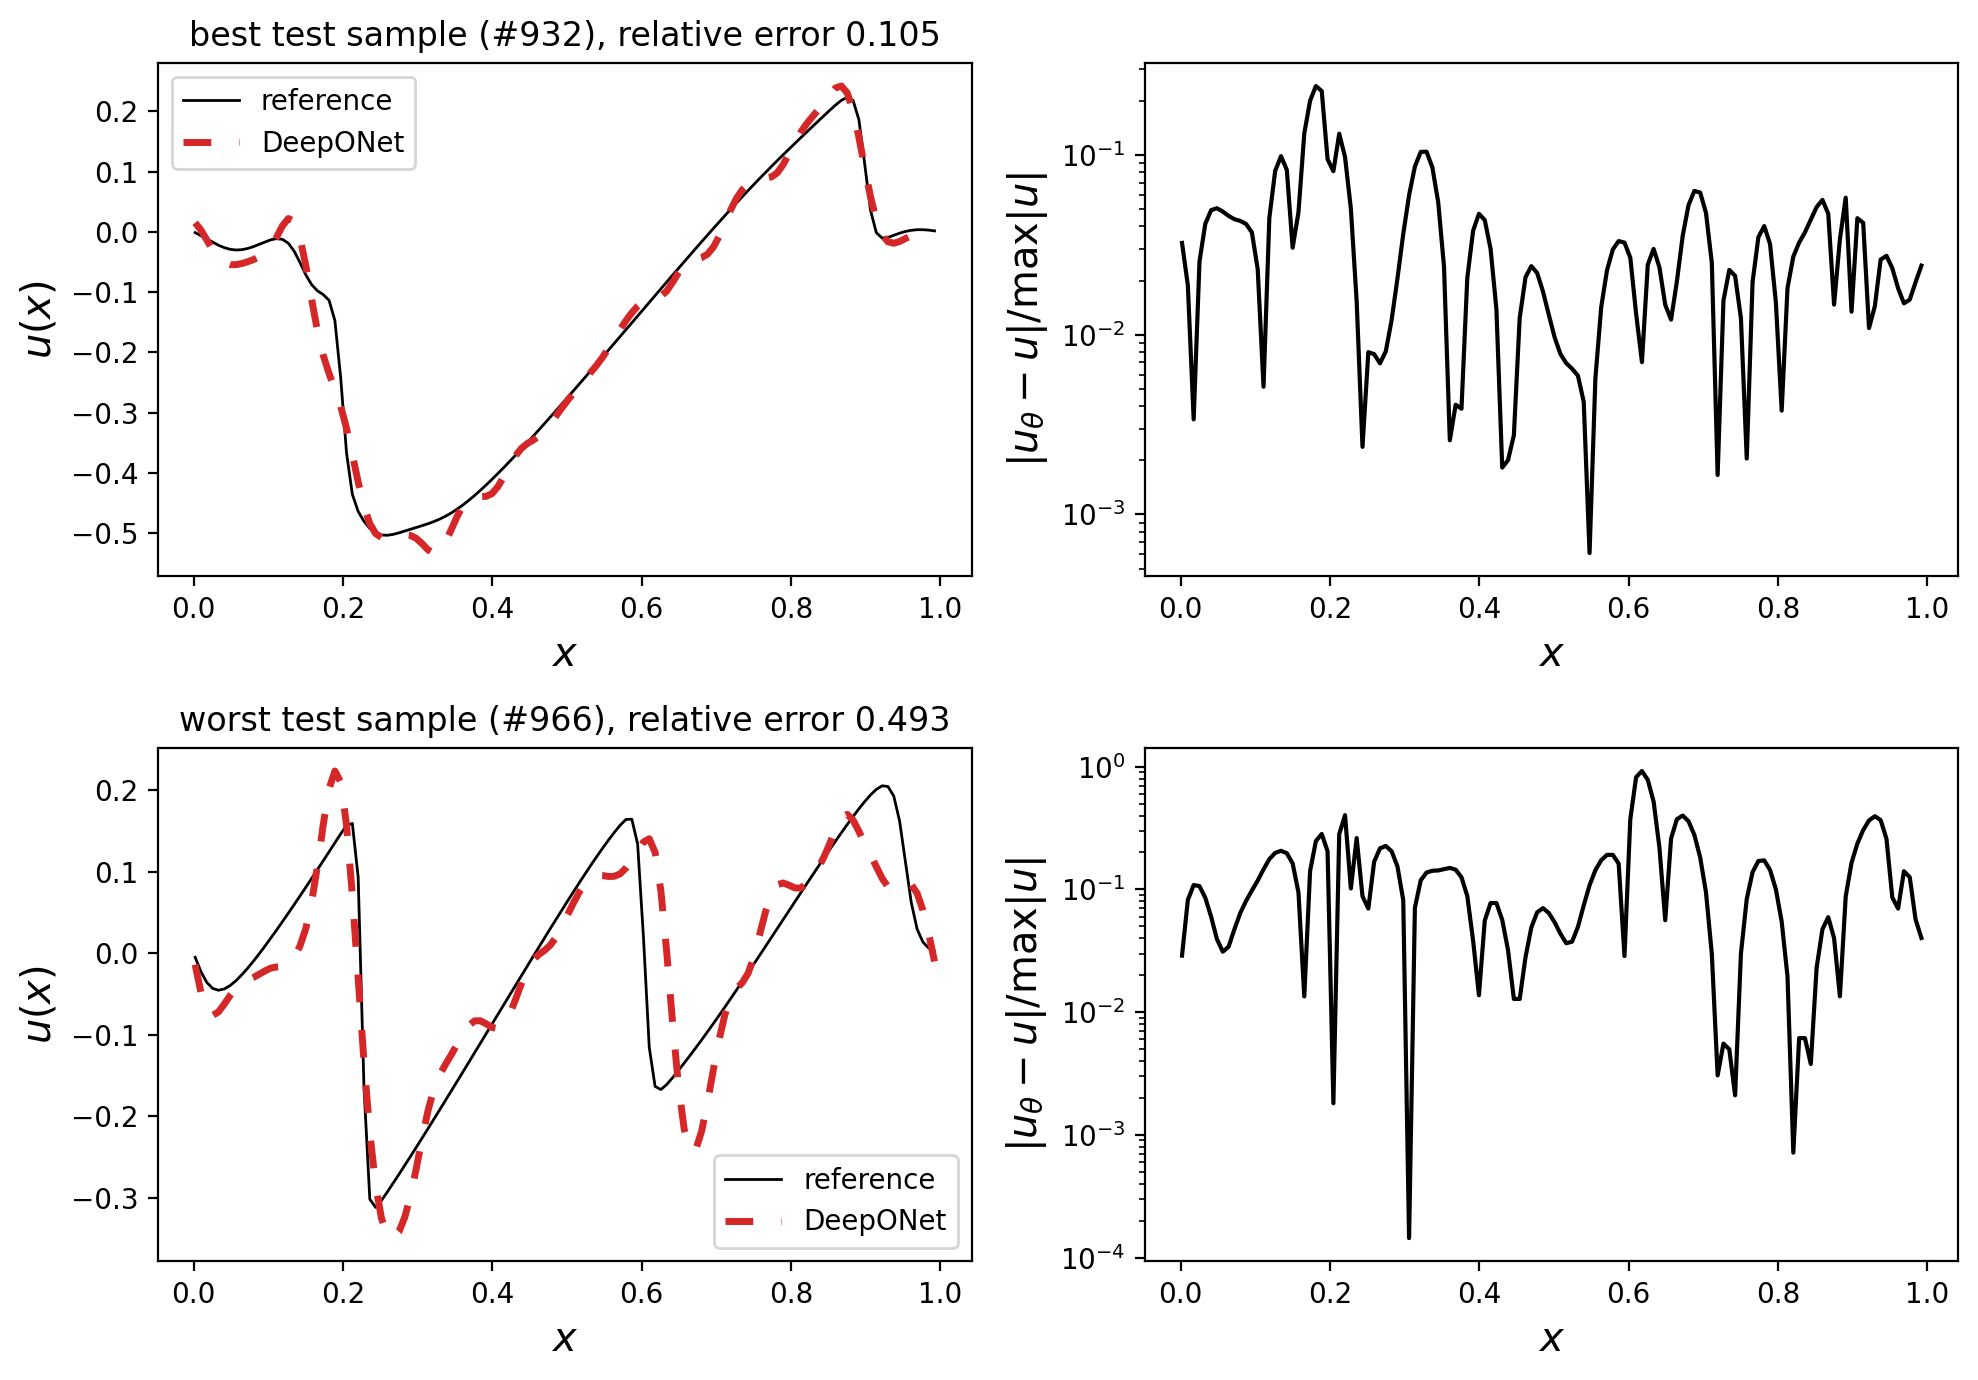

In [9]:
model, history, errors, predictions, targets, coordinates = train('Burgers')
plot_results(history, errors, predictions, targets, coordinates, figure_name='DeepONet_Burgers')

## Diffusion equation

Number of parameters: 414600
Training time: 30.2 s
Relative error      mean    median       min       max
  train           0.0507    0.0294    0.0033    0.9871
  test            0.1927    0.1056    0.0218    1.6573


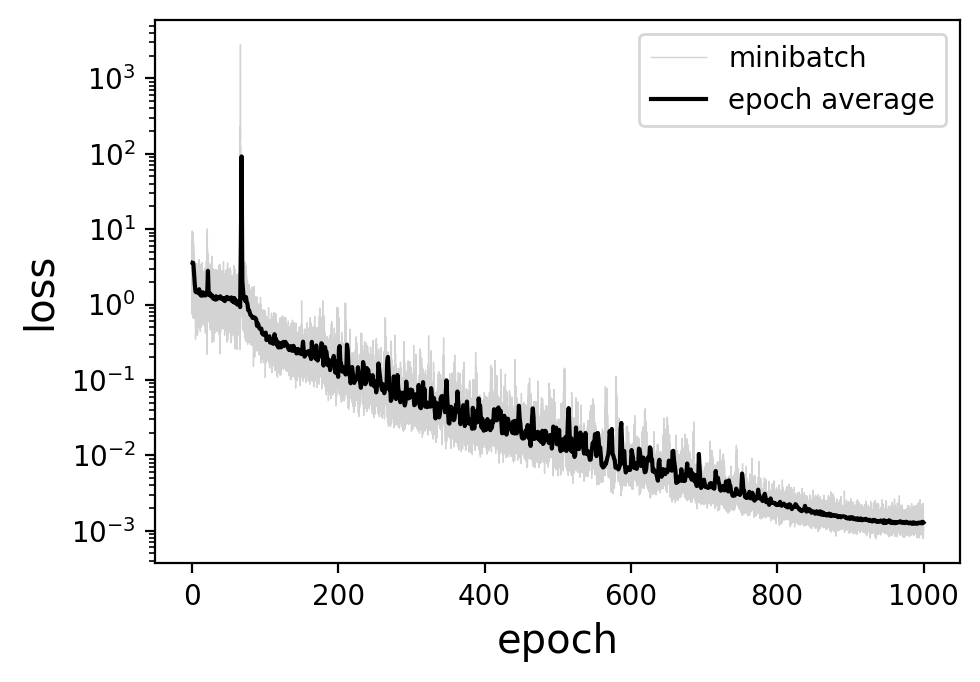

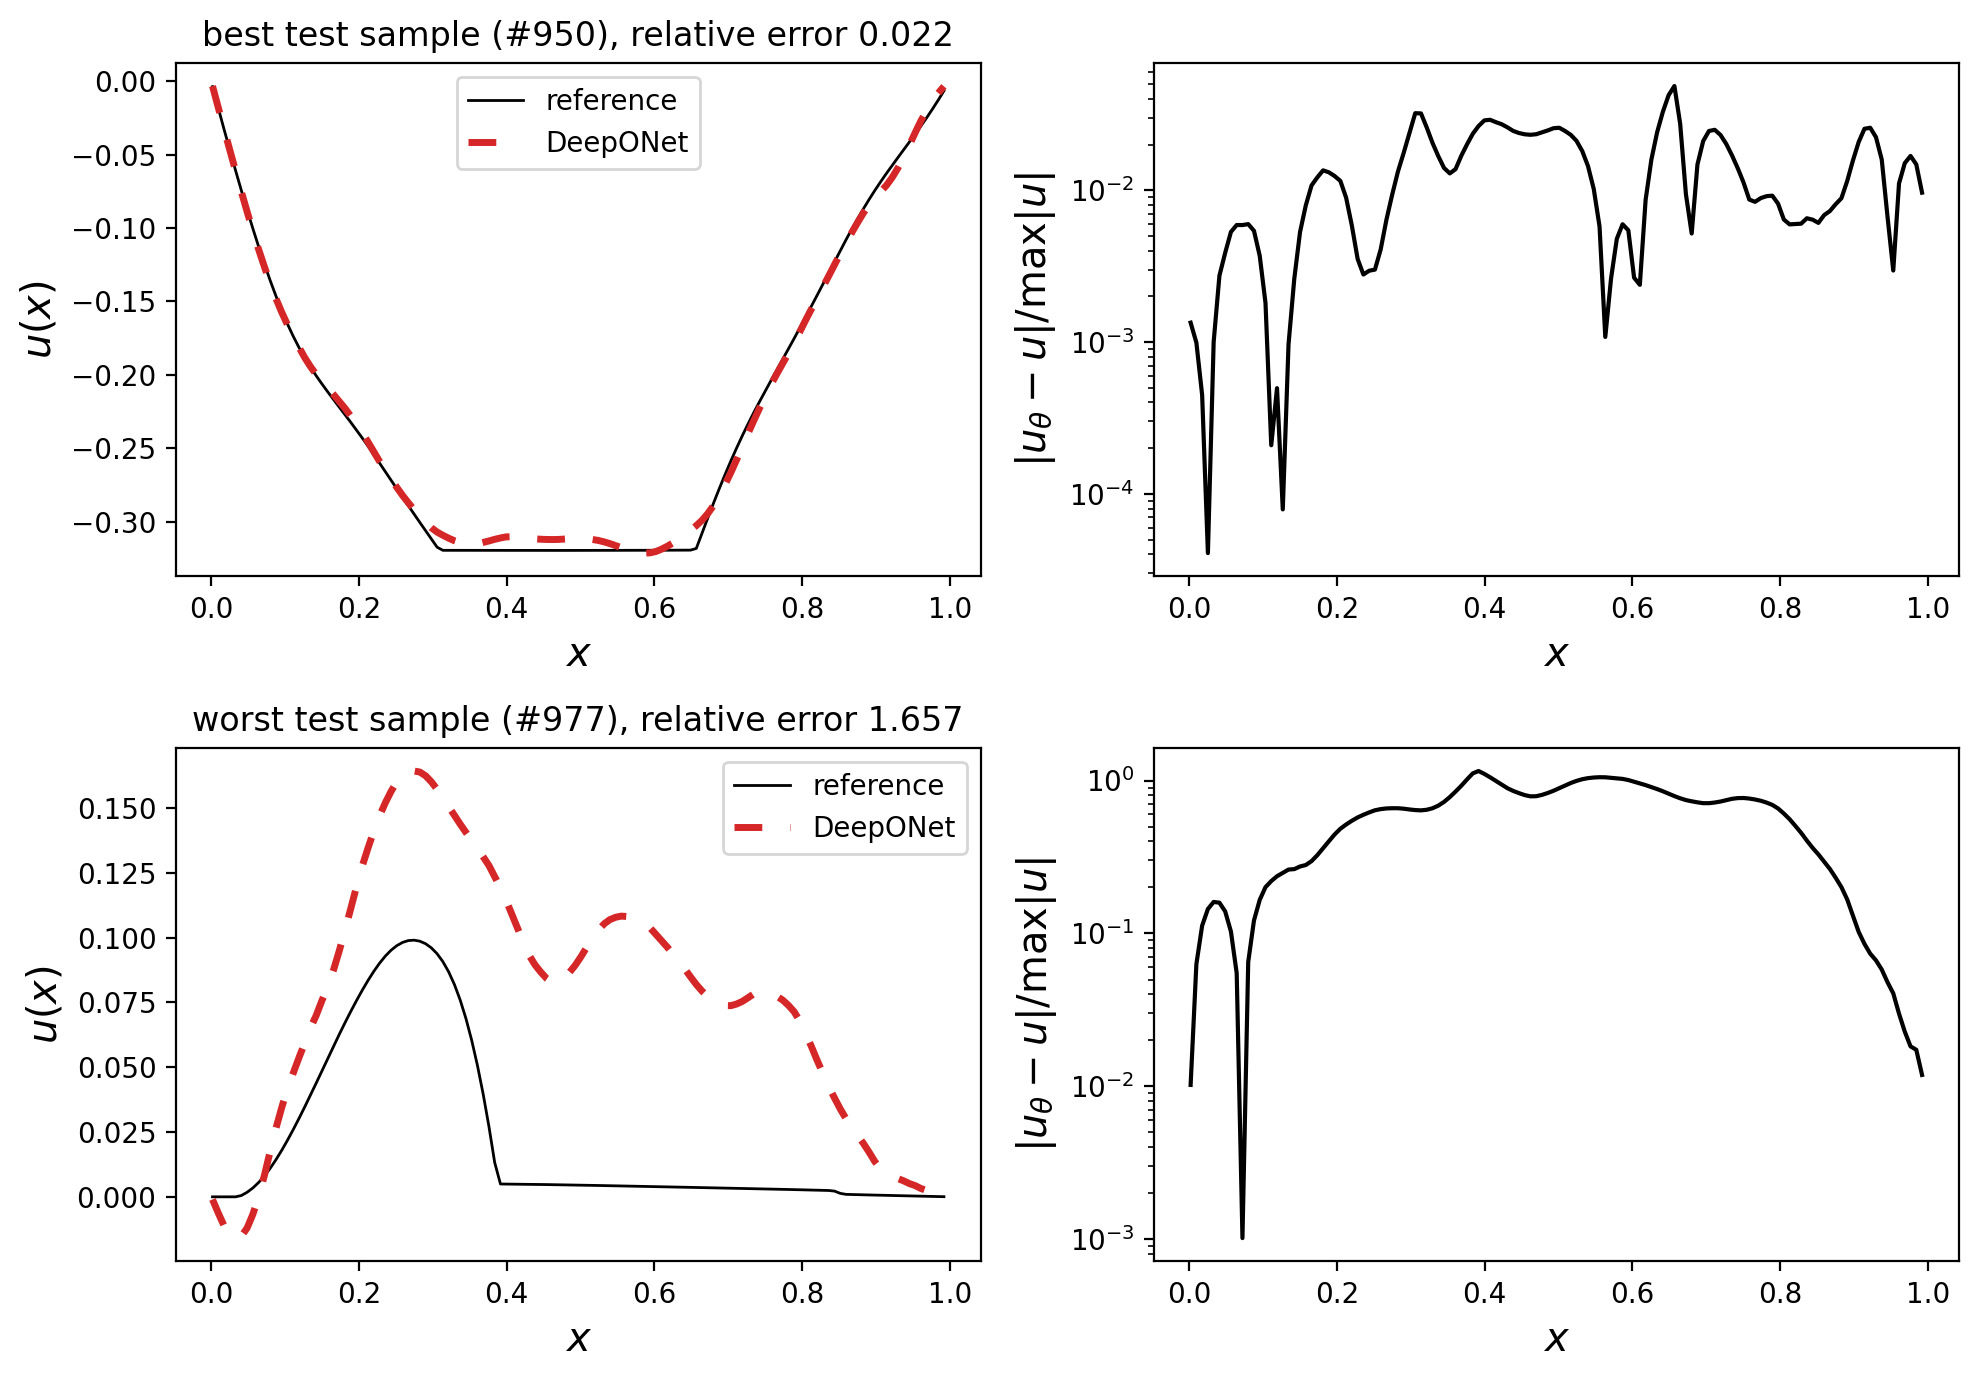

In [10]:
model, history, errors, predictions, targets, coordinates = train('Diffusion')
plot_results(history, errors, predictions, targets, coordinates, figure_name='DeepONet_Diffusion')

## Diffusion equation with a constant source term

The right-hand side is the same for all samples, so the only input channel is the coefficient $a(x)$.

Number of parameters: 408600
Training time: 29.5 s
Relative error      mean    median       min       max
  train           0.0393    0.0303    0.0059    0.2275
  test            0.0826    0.0639    0.0067    0.4686


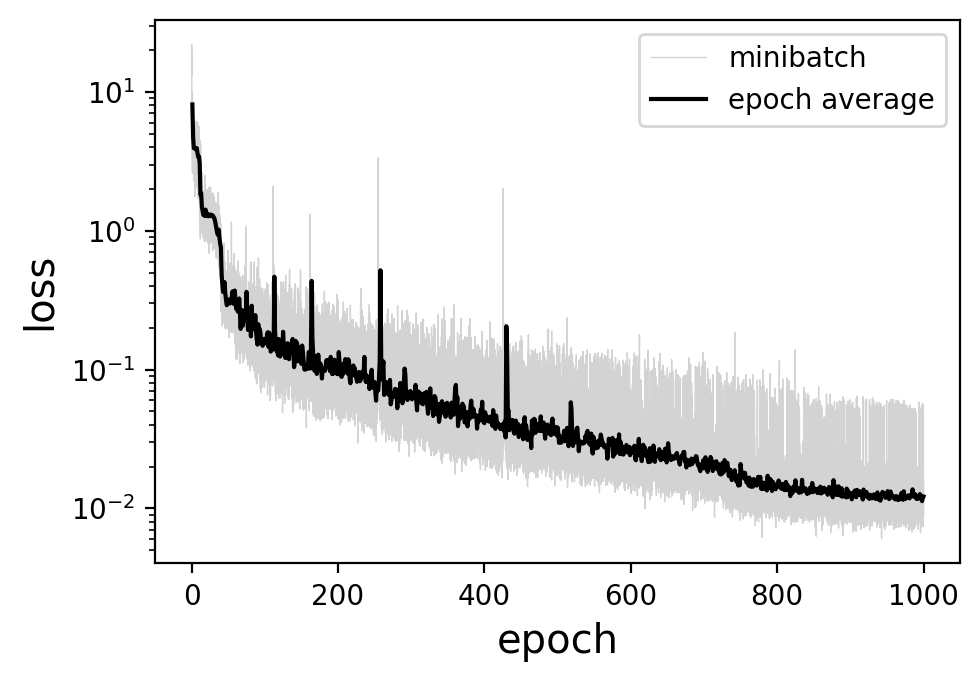

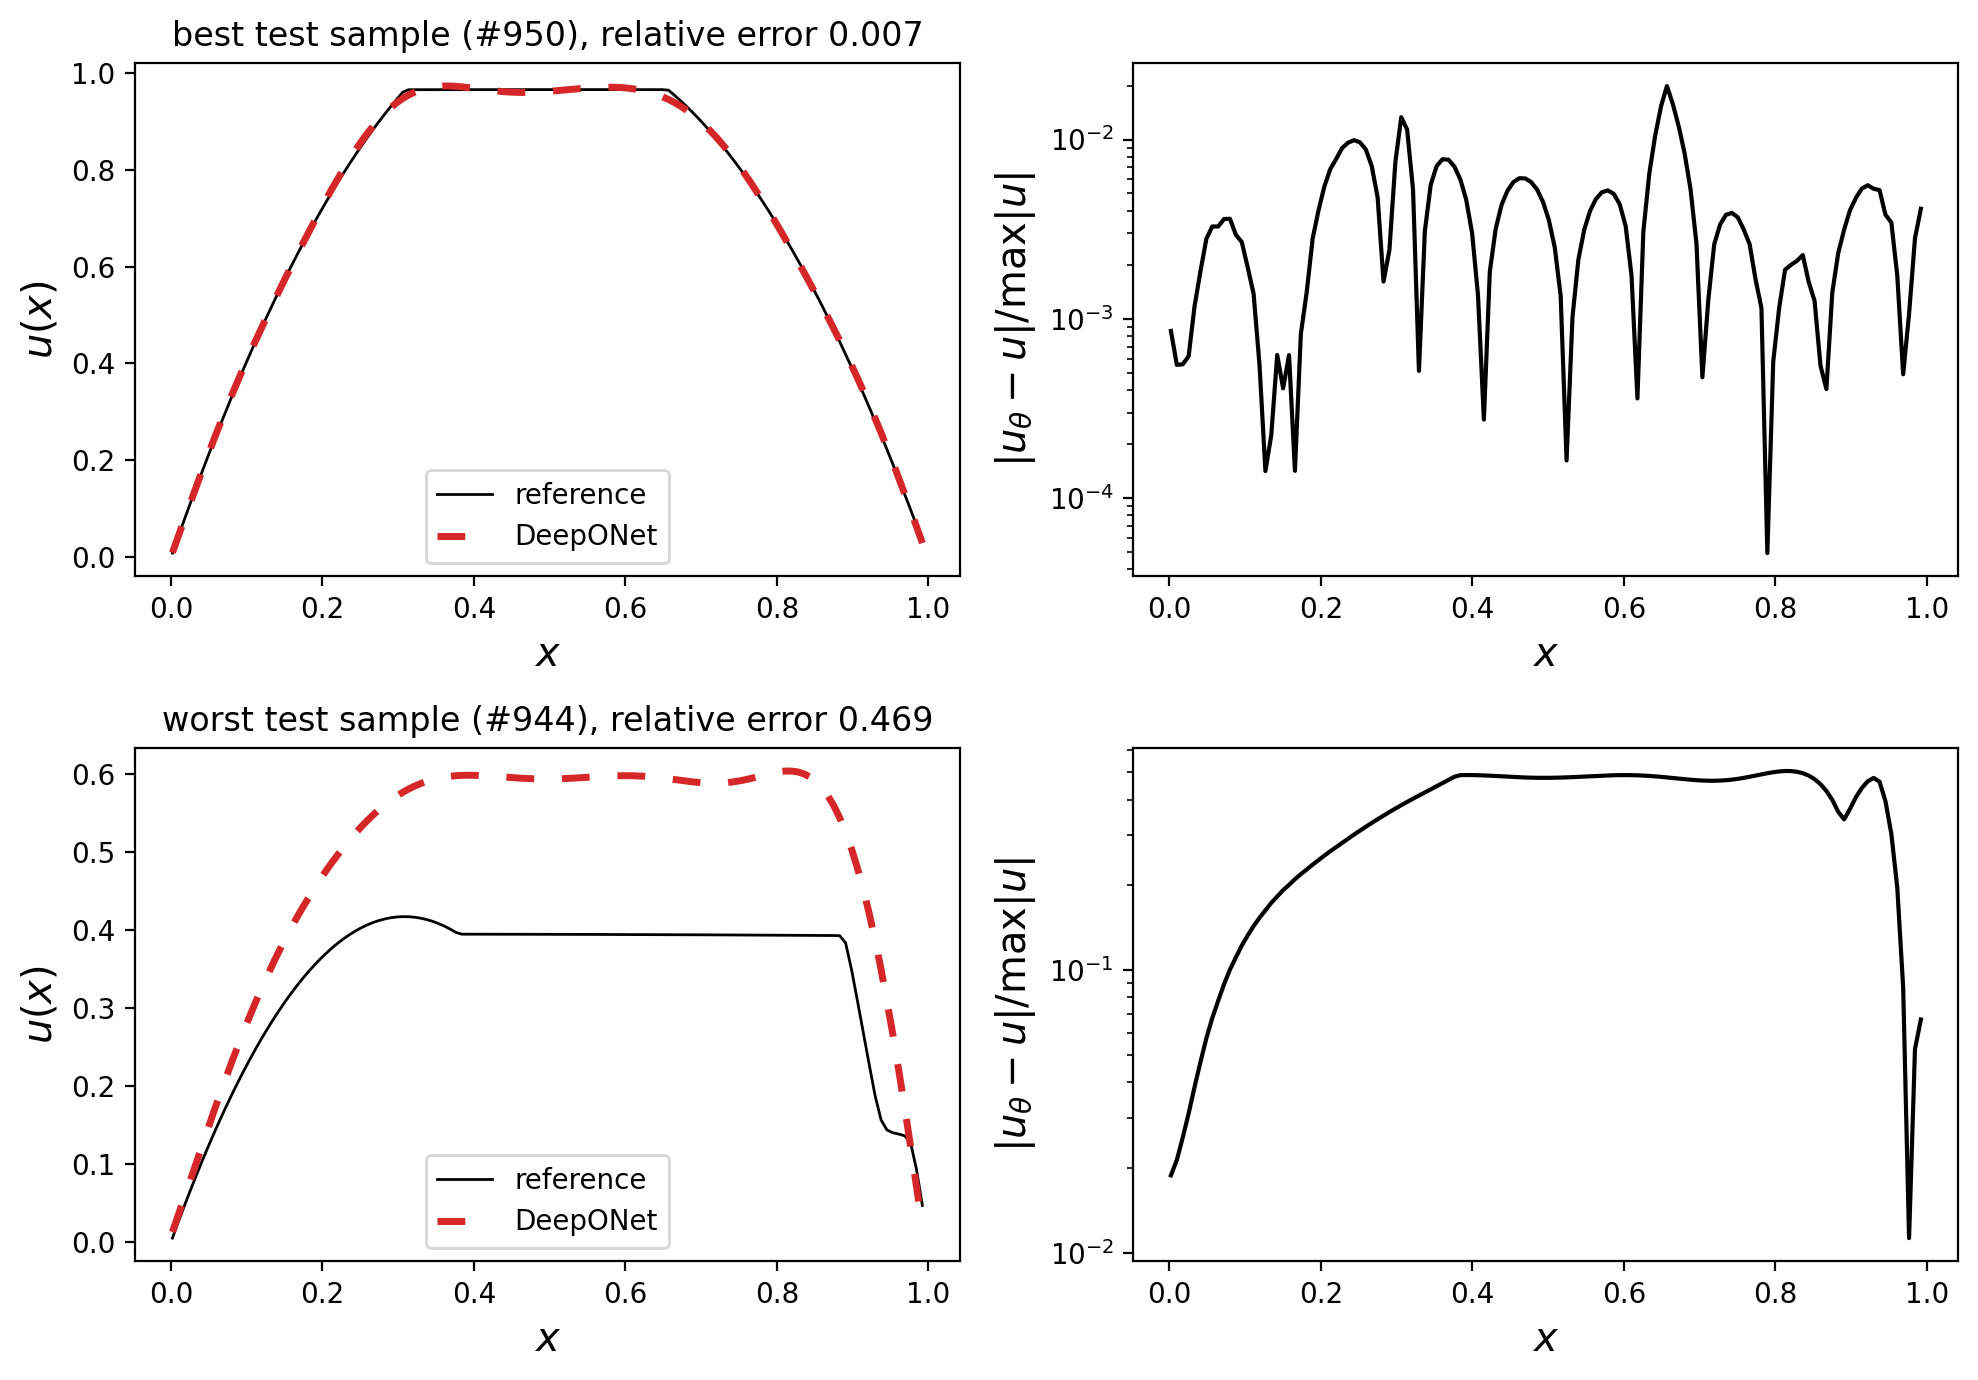

In [11]:
model, history, errors, predictions, targets, coordinates = train('Diffusion_constant_source')
plot_results(history, errors, predictions, targets, coordinates, figure_name='DeepONet_Diffusion_constant_source')

# Summary

Relative errors $\|u_\theta-u\|_2/\|u\|_2$ of the trained DeepONet on the grid of 128 points (900 training and 100 test samples, 1000 epochs, 30-45 s of training for each problem):

| Dataset | Set | Mean | Median | Min | Max |
|---|---|---|---|---|---|
| Burgers | train | 0.1123 | 0.1096 | 0.0185 | 0.2430 |
| Burgers | test | 0.2772 | 0.2689 | 0.1051 | 0.4926 |
| Diffusion | train | 0.0507 | 0.0294 | 0.0033 | 0.9871 |
| Diffusion | test | 0.1927 | 0.1056 | 0.0218 | 1.6573 |
| Diffusion, constant source | train | 0.0393 | 0.0303 | 0.0059 | 0.2275 |
| Diffusion, constant source | test | 0.0826 | 0.0639 | 0.0067 | 0.4686 |

**Tuning.** We started from the defaults of the reference implementation (test mean errors 0.247, 0.293, 0.080 for the three problems). To avoid tuning on the test set, we used the last 100 training samples as a validation set. One change at a time, with a single seed:

- *no effect or worse:* a larger learning rate (3e-3) lowers the training error but raises the validation error; a larger frequency scale of the trunk (30 instead of 10); a larger batch; shallower networks; fewer epochs; strong weight decay ($\geq 0.1$);
- *helped:* the cosine decay of the learning rate, fewer projection functions `n_obs` (30 instead of 60), more basis functions `n_basis` (200 instead of 100), and a small weight decay (0.01).

The final configuration is the same for all problems. It improves the diffusion problems (test mean error 0.293 $\to$ 0.198 and 0.080 $\to$ 0.076 on the grid of 512 points) but is slightly worse for Burgers (0.247 $\to$ 0.267); the Burgers differences between the configurations are comparable with the seed-to-seed noise, which we did not measure.

**Resolution.** The tuning was done on the grid of 512 points. Repeating the final training on the grid of 128 points gives practically the same test errors (0.267, 0.198, 0.076 on 512 points), so the coarser grid does not change the accuracy of the DeepONet.

**Conclusion.** The tuning gave only moderate gains: the validation error is much larger than the training error, so the DeepONet is limited by generalisation from 900 samples and not by the optimisation. The DeepONet is clearly worse than the FNO on all three problems (test mean errors 0.28 vs 0.05 for Burgers, 0.19 vs 0.15 for diffusion, 0.083 vs 0.066 for diffusion with a constant source), and the gap is the largest for Burgers, where the solutions have shocks (we did not test why, but a plausible reason is that a low-dimensional learned basis with coefficients computed from a projection of the input represents shocks poorly). For both operators the worst test samples of the diffusion problem are not predicted at all (error above 1).